In [7]:
# ==========================================
# 1. SUMBER DATA & IMPORT LIBRARY
# ==========================================

# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Membaca dataset Excel
file_path = 'Temperatur_Surabaya_2022-2024.xlsx'

df = pd.read_excel(file_path)

# Menampilkan informasi struktur DataFrame
print('=== INFORMASI STRUKTUR DATA ===')
df.info()

print('\n' + '=' * 60)

# Menampilkan 5 data teratas
print('=== PREVIEW DATA ===')
print(df.head())

print('\n' + '=' * 60)

# Memeriksa missing value
print('=== PEMERIKSAAN MISSING VALUE ===')
print(df.isnull().sum())


=== INFORMASI STRUKTUR DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Tahun           36 non-null     int64  
 1   Bulan           36 non-null     object 
 2   Minimum (°C)    36 non-null     float64
 3   Rata-rata (°C)  36 non-null     float64
 4   Maksimum (°C)   36 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 1.5+ KB

=== PREVIEW DATA ===
   Tahun     Bulan  Minimum (°C)  Rata-rata (°C)  Maksimum (°C)
0   2022   Januari          23.8            27.7           35.5
1   2022  Februari          22.5            27.4           34.0
2   2022     Maret          23.0            28.1           35.0
3   2022     April          23.2            28.9           34.8
4   2022       Mei          23.2            29.0           34.8

=== PEMERIKSAAN MISSING VALUE ===
Tahun             0
Bulan             0
Minimum 

=== STATISTIK DESKRIPTIF ===
       Minimum (°C)  Rata-rata (°C)  Maksimum (°C)
count         36.00           36.00          36.00
mean          23.66           28.83          35.12
std            0.95            0.85           1.11
min           21.80           27.40          33.50
25%           23.00           28.28          34.40
50%           23.80           28.70          34.90
75%           24.20           29.26          35.52
max           25.60           30.70          37.80
------------------------------------------------------------


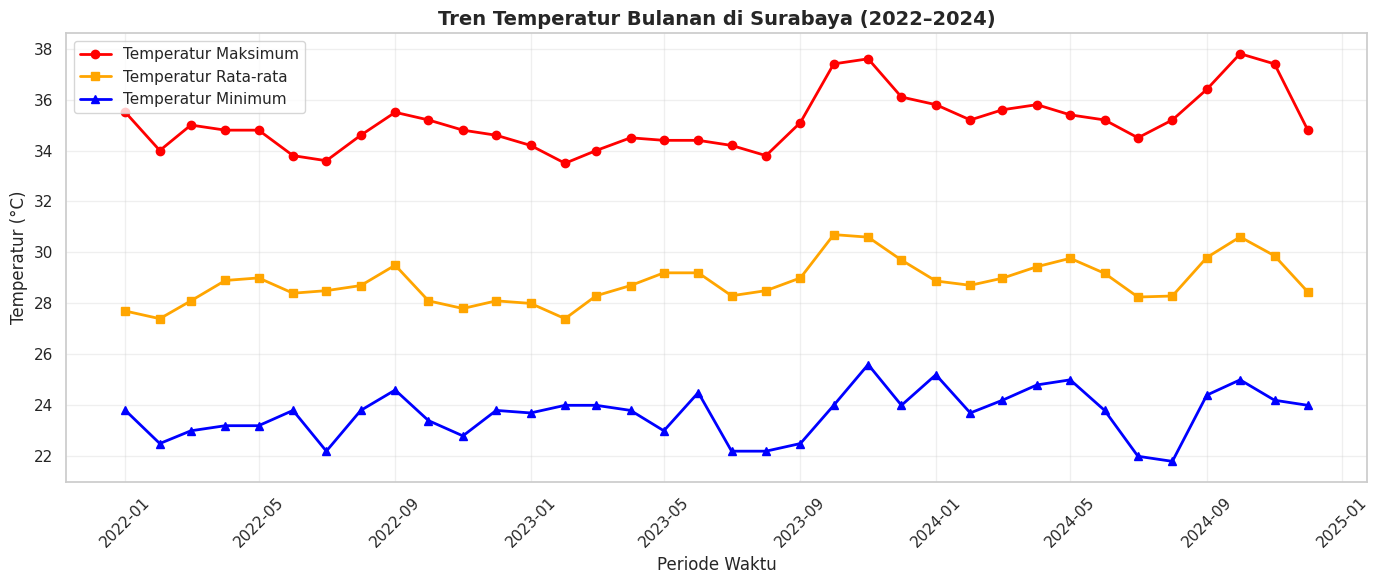

=== RATA-RATA TEMPERATUR TAHUNAN ===
       Minimum (°C)  Rata-rata (°C)  Maksimum (°C)
Tahun                                             
2022          23.34           28.35          34.68
2023          23.62           28.97          34.93
2024          24.01           29.19          35.76
------------------------------------------------------------


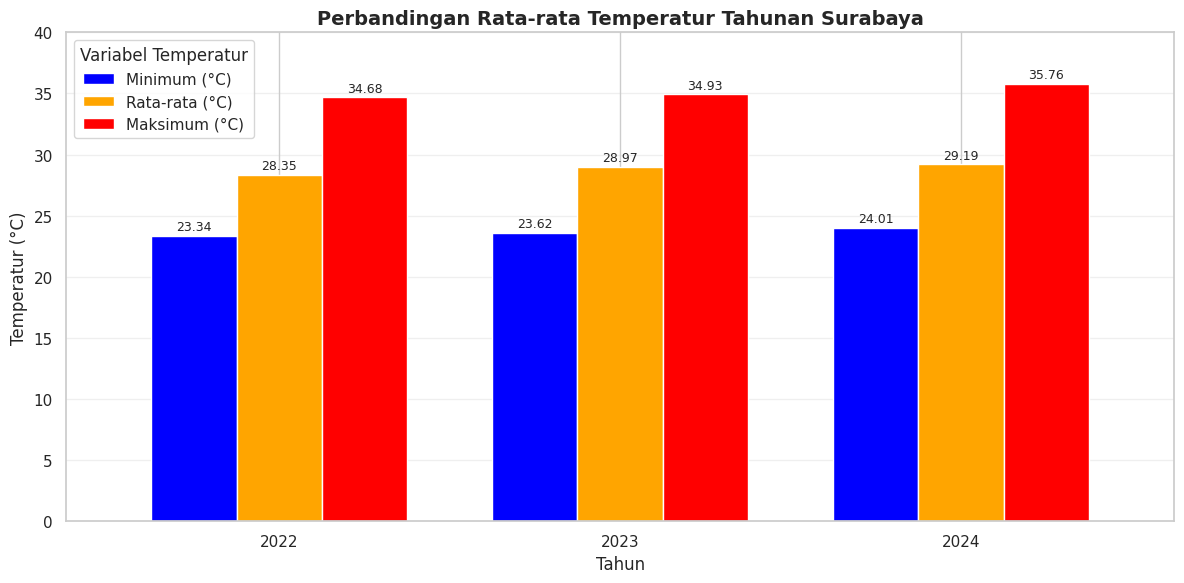

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset
excel_path = 'Temperatur_Surabaya_2022-2024.xlsx'
df = pd.read_excel(excel_path)

# ==========================================
# 2A. STATISTIK DESKRIPTIF
# ==========================================
print('=== STATISTIK DESKRIPTIF ===')
kolom_suhu = ['Minimum (°C)', 'Rata-rata (°C)', 'Maksimum (°C)']
descriptive_stats = df[kolom_suhu].describe()
print(descriptive_stats.round(2))
print('-' * 60)

# ==========================================
# 2B. VISUALISASI TIME SERIES
# ==========================================
bulan_mapping = {
    'Januari': 1, 'Februari': 2, 'Maret': 3, 'April': 4, 'Mei': 5, 'Juni': 6,
    'Juli': 7, 'Agustus': 8, 'September': 9, 'Oktober': 10, 'November': 11, 'Desember': 12,
}
df['Nomor_Bulan'] = df['Bulan'].str.strip().map(bulan_mapping)
if df['Nomor_Bulan'].isnull().any():
    raise ValueError('Terdapat nama bulan yang tidak dikenali!')

df['Periode'] = pd.to_datetime(dict(year=df['Tahun'], month=df['Nomor_Bulan'], day=1))
df = df.sort_values('Periode').reset_index(drop=True)

fig1, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(df['Periode'], df['Maksimum (°C)'], marker='o', color='red',
         label='Temperatur Maksimum', linewidth=2)
ax1.plot(df['Periode'], df['Rata-rata (°C)'], marker='s', color='orange',
         label='Temperatur Rata-rata', linewidth=2)
ax1.plot(df['Periode'], df['Minimum (°C)'], marker='^', color='blue',
         label='Temperatur Minimum', linewidth=2)
ax1.set_title('Tren Temperatur Bulanan di Surabaya (2022–2024)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Periode Waktu', fontsize=12)
ax1.set_ylabel('Temperatur (°C)', fontsize=12)
ax1.legend(loc='upper left')
ax1.grid(alpha=0.3)
plt.setp(ax1.get_xticklabels(), rotation=45)
fig1.tight_layout()
fig1.savefig('timeseries_temperatur.png', dpi=150)   # cadangan: simpan ke file
plt.show()

# ==========================================
# 2C. AGREGASI TEMPERATUR TAHUNAN
# ==========================================
print('=== RATA-RATA TEMPERATUR TAHUNAN ===')
annual_summary = df.groupby('Tahun')[kolom_suhu].mean().round(2)
print(annual_summary)
print('-' * 60)

ax2 = annual_summary.plot(kind='bar', figsize=(12, 6), width=0.75,
                          color=['blue', 'orange', 'red'])
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', fontsize=9, padding=2)
ax2.set_title('Perbandingan Rata-rata Temperatur Tahunan Surabaya', fontsize=14, fontweight='bold')
ax2.set_xlabel('Tahun')
ax2.set_ylabel('Temperatur (°C)')
ax2.set_ylim(0, 40)
plt.setp(ax2.get_xticklabels(), rotation=0)
ax2.legend(title='Variabel Temperatur')
ax2.grid(axis='y', alpha=0.3)
ax2.figure.tight_layout()
ax2.figure.savefig('tahunan_temperatur.png', dpi=150)
plt.show()


=== Minimum (°C) ===
Temperatur tertinggi: 25.6 °C pada November 2023
Temperatur terendah: 21.8 °C pada Agustus 2024

=== Rata-rata (°C) ===
Temperatur tertinggi: 30.7 °C pada Oktober 2023
Temperatur terendah: 27.4 °C pada Februari 2022

=== Maksimum (°C) ===
Temperatur tertinggi: 37.8 °C pada Oktober 2024
Temperatur terendah: 33.5 °C pada Februari 2023
=== PERUBAHAN TEMPERATUR RATA-RATA ===
       Rata-rata Temperatur (°C)  Perubahan (°C)  Perubahan (%)
Tahun                                                          
2022                      28.350             NaN            NaN
2023                      28.967           0.617          2.175
2024                      29.187           0.220          0.759
=== RATA-RATA TEMPERATUR BERDASARKAN BULAN ===
           Minimum (°C)  Rata-rata (°C)  Maksimum (°C)
Januari           24.23           28.19          35.17
Februari          23.40           27.84          34.23
Maret             23.73           28.46          34.87
April            

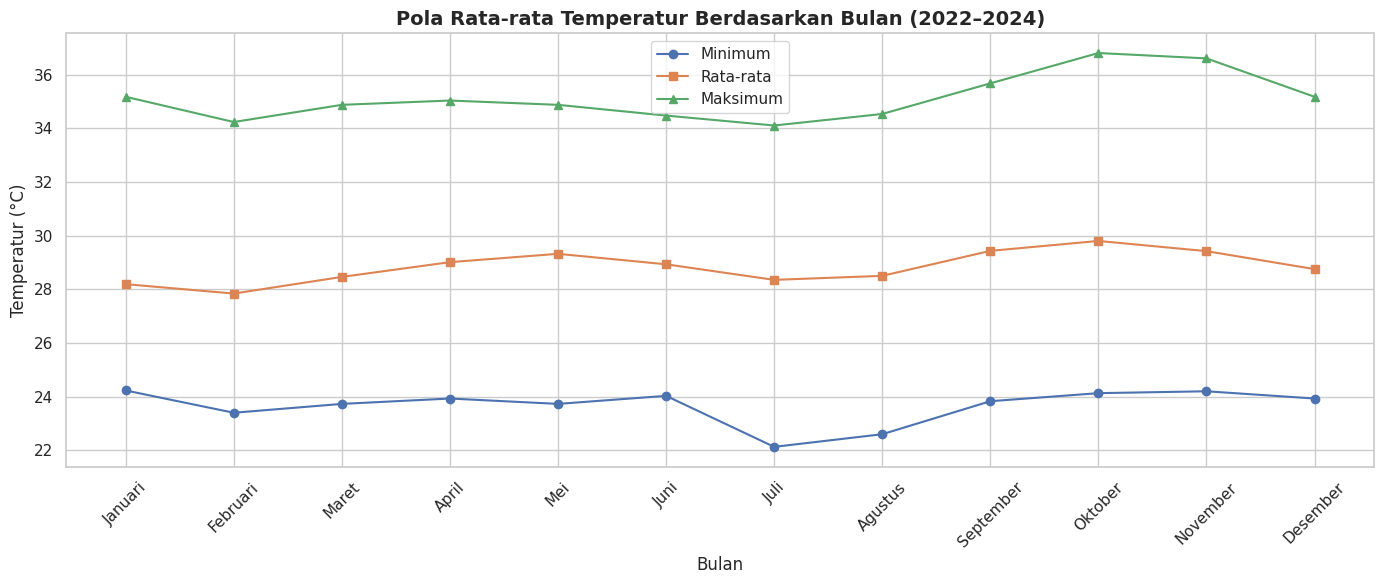


Bulan dengan rata-rata temperatur tertinggi: Oktober
Bulan dengan rata-rata temperatur terendah: Februari


In [4]:
# ==========================================
# 3A. IDENTIFIKASI NILAI EKSTREM
# ==========================================

variabel_temperatur = [
    'Minimum (°C)',
    'Rata-rata (°C)',
    'Maksimum (°C)'
]

for kolom in variabel_temperatur:

    # Mencari indeks temperatur tertinggi
    idx_max = df[kolom].idxmax()

    # Mencari indeks temperatur terendah
    idx_min = df[kolom].idxmin()

    data_max = df.loc[idx_max]
    data_min = df.loc[idx_min]

    print(f'\n=== {kolom} ===')

    print(
        f"Temperatur tertinggi: {data_max[kolom]} °C "
        f"pada {data_max['Bulan']} {data_max['Tahun']}"
    )

    print(
        f"Temperatur terendah: {data_min[kolom]} °C "
        f"pada {data_min['Bulan']} {data_min['Tahun']}"
    )

# ==========================================
# 3B. ANALISIS PERUBAHAN TEMPERATUR TAHUNAN
# ==========================================

# Menghitung rata-rata temperatur setiap tahun
annual_mean = df.groupby('Tahun')['Rata-rata (°C)'].mean()

# Menghitung perubahan temperatur antar tahun
annual_change = annual_mean.diff()

# Menghitung persentase perubahan
annual_percentage = annual_mean.pct_change() * 100

print('=== PERUBAHAN TEMPERATUR RATA-RATA ===')

annual_comparison = pd.DataFrame({
    'Rata-rata Temperatur (°C)': annual_mean,
    'Perubahan (°C)': annual_change,
    'Perubahan (%)': annual_percentage
})

print(annual_comparison.round(3))

# ==========================================
# 3C. ANALISIS POLA MUSIMAN
# ==========================================

# Menghitung rata-rata temperatur berdasarkan bulan
monthly_summary = (
    df.groupby('Nomor_Bulan')[
        ['Minimum (°C)', 'Rata-rata (°C)', 'Maksimum (°C)']
    ]
    .mean()
    .round(2)
)

# Mengurutkan berdasarkan bulan
monthly_summary.index = [
    list(bulan_mapping.keys())[i - 1]
    for i in monthly_summary.index
]

print('=== RATA-RATA TEMPERATUR BERDASARKAN BULAN ===')
print(monthly_summary)

# Visualisasi pola temperatur bulanan
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_summary.index,
    monthly_summary['Minimum (°C)'],
    marker='o',
    label='Minimum'
)

plt.plot(
    monthly_summary.index,
    monthly_summary['Rata-rata (°C)'],
    marker='s',
    label='Rata-rata'
)

plt.plot(
    monthly_summary.index,
    monthly_summary['Maksimum (°C)'],
    marker='^',
    label='Maksimum'
)

plt.title(
    'Pola Rata-rata Temperatur Berdasarkan Bulan (2022–2024)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Bulan')
plt.ylabel('Temperatur (°C)')
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

# Mencari bulan dengan rata-rata temperatur tertinggi
bulan_terpanas = monthly_summary['Rata-rata (°C)'].idxmax()

# Mencari bulan dengan rata-rata temperatur terendah
bulan_terdingin = monthly_summary['Rata-rata (°C)'].idxmin()

print('\nBulan dengan rata-rata temperatur tertinggi:',
      bulan_terpanas)

print('Bulan dengan rata-rata temperatur terendah:',
      bulan_terdingin)

=== UJI STASIONERITAS AUGMENTED DICKEY-FULLER ===
Test Statistic : -1.645449
p-value        : 0.459415
Used Lag       : 3
Observations   : 32

Critical Values:
1% : -3.653520
5% : -2.957219
10% : -2.617588
------------------------------------------------------------
=== INTERPRETASI HASIL ADF ===
Keputusan: Gagal menolak H0
Kesimpulan: Data temperatur rata-rata BELUM TERBUKTI STASIONER.
------------------------------------------------------------
Berdasarkan Critical Value 5%: Data BELUM TERBUKTI STASIONER.
------------------------------------------------------------


/tmp/ipykernel_1873/778100138.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(data_adf, autolag='AIC')


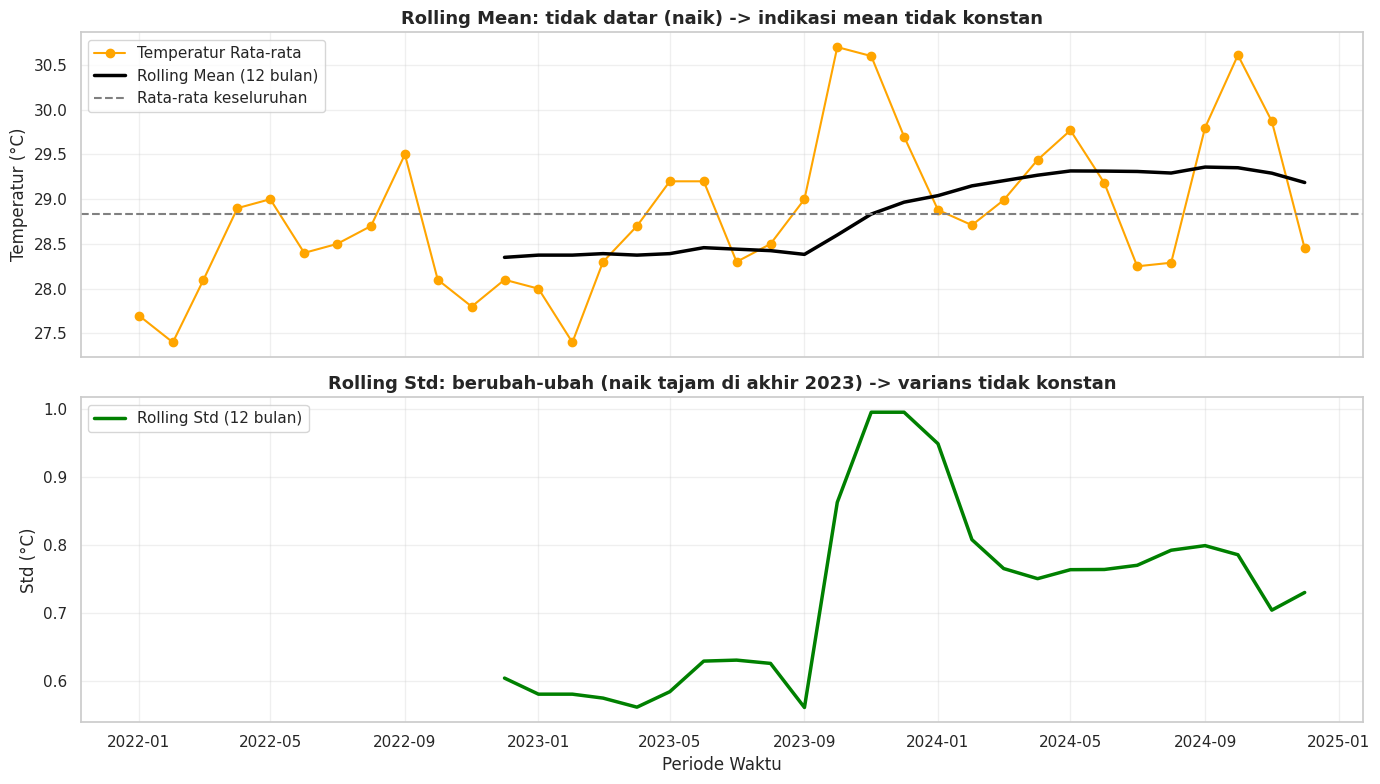

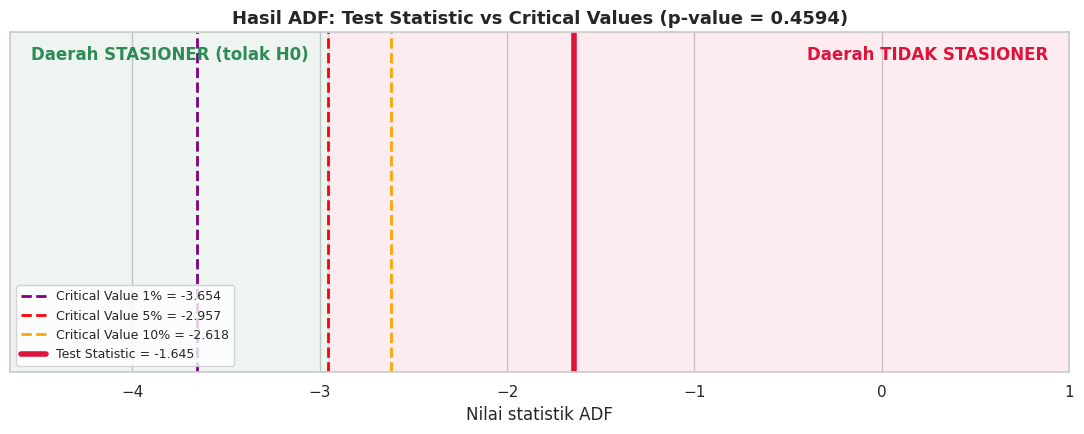

=== BUKTI TAMBAHAN: PERGESERAN MEAN ===
Kemiringan tren linear : +0.506 °C/tahun
Mean tahun 2022        : 28.35 °C
Mean tahun 2023        : 28.97 °C
Mean tahun 2024        : 29.19 °C


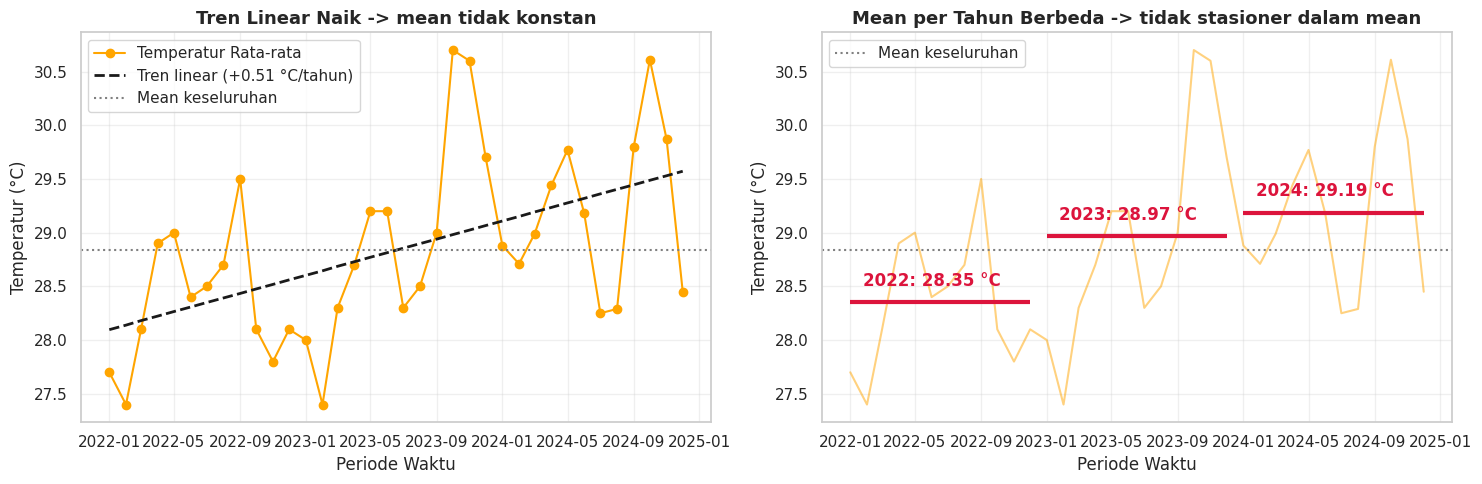

In [5]:
# ==========================================
# 4. UJI STASIONERITAS ADF TEST
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

print('=== UJI STASIONERITAS AUGMENTED DICKEY-FULLER ===')

# Mengambil variabel temperatur rata-rata (indeks = periode waktu agar sumbu-x berupa tanggal)
data_adf = df.set_index('Periode')['Rata-rata (°C)'].dropna()

# Melakukan pengujian ADF
adf_result = adfuller(data_adf, autolag='AIC')

# Mengambil hasil pengujian
test_statistic = adf_result[0]
p_value = adf_result[1]
used_lag = adf_result[2]
n_observations = adf_result[3]
critical_values = adf_result[4]

# Menampilkan hasil pengujian
print(f'Test Statistic : {test_statistic:.6f}')
print(f'p-value        : {p_value:.6f}')
print(f'Used Lag       : {used_lag}')
print(f'Observations   : {n_observations}')

print('\nCritical Values:')
for key, value in critical_values.items():
    print(f'{key} : {value:.6f}')

print('-' * 60)

# Interpretasi hasil ADF
alpha = 0.05
print('=== INTERPRETASI HASIL ADF ===')

if p_value <= alpha:
    print('Keputusan: Tolak H0')
    print('Kesimpulan: Data temperatur rata-rata STASIONER.')
else:
    print('Keputusan: Gagal menolak H0')
    print('Kesimpulan: Data temperatur rata-rata BELUM TERBUKTI STASIONER.')

print('-' * 60)

# Pemeriksaan berdasarkan Critical Value 5%
if test_statistic < critical_values['5%']:
    print('Berdasarkan Critical Value 5%: Data STASIONER.')
else:
    print('Berdasarkan Critical Value 5%: Data BELUM TERBUKTI STASIONER.')

print('-' * 60)

# ==========================================
# 4A. VISUALISASI 1: ROLLING MEAN & ROLLING STD
# Seri stasioner -> rata-rata & simpangan baku bergerak relatif datar
# ==========================================
window = 12
rolling_mean = data_adf.rolling(window=window).mean()
rolling_std = data_adf.rolling(window=window).std()

fig1, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(data_adf.index, data_adf, marker='o', color='orange', label='Temperatur Rata-rata')
axes[0].plot(rolling_mean.index, rolling_mean, color='black', linewidth=2.5,
             label=f'Rolling Mean ({window} bulan)')
axes[0].axhline(data_adf.mean(), color='gray', linestyle='--', label='Rata-rata keseluruhan')
axes[0].set_title('Rolling Mean: tidak datar (naik) -> indikasi mean tidak konstan',
                  fontsize=13, fontweight='bold')
axes[0].set_ylabel('Temperatur (°C)')
axes[0].legend(loc='upper left')
axes[0].grid(alpha=0.3)

axes[1].plot(rolling_std.index, rolling_std, color='green', linewidth=2.5,
             label=f'Rolling Std ({window} bulan)')
axes[1].set_title('Rolling Std: berubah-ubah (naik tajam di akhir 2023) -> varians tidak konstan',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Periode Waktu')
axes[1].set_ylabel('Std (°C)')
axes[1].legend(loc='upper left')
axes[1].grid(alpha=0.3)

fig1.tight_layout()
fig1.savefig('adf_1_rolling.png', dpi=150)
plt.show()

# ==========================================
# 4B. VISUALISASI 2: TEST STATISTIC vs CRITICAL VALUES
# Stasioner jika test statistic berada di KIRI (lebih negatif) dari critical value
# ==========================================
fig2, ax = plt.subplots(figsize=(11, 4.5))

warna_cv = {'1%': 'purple', '5%': 'red', '10%': 'orange'}
for key, value in critical_values.items():
    ax.axvline(value, color=warna_cv[key], linestyle='--', linewidth=2,
               label=f'Critical Value {key} = {value:.3f}')

stat_color = 'seagreen' if p_value <= alpha else 'crimson'
ax.axvline(test_statistic, color=stat_color, linewidth=4,
           label=f'Test Statistic = {test_statistic:.3f}')
ax.axvspan(min(test_statistic, critical_values['1%']) - 1, critical_values['5%'],
           color='seagreen', alpha=0.08)
ax.axvspan(critical_values['5%'], 1, color='crimson', alpha=0.08)
ax.text(0.02, 0.92, 'Daerah STASIONER (tolak H0)', transform=ax.transAxes,
        color='seagreen', fontweight='bold')
ax.text(0.98, 0.92, 'Daerah TIDAK STASIONER', transform=ax.transAxes,
        color='crimson', fontweight='bold', ha='right')
ax.set_xlim(min(test_statistic, critical_values['1%']) - 1, 1)
ax.set_yticks([])
ax.set_xlabel('Nilai statistik ADF')
ax.set_title(f'Hasil ADF: Test Statistic vs Critical Values (p-value = {p_value:.4f})',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower left', fontsize=9)
fig2.tight_layout()
fig2.savefig('adf_2_critical_values.png', dpi=150)
plt.show()

# ==========================================
# 4C. VISUALISASI 3: TREN LINEAR & RATA-RATA PER TAHUN
# Seri stasioner: mean konstan. Di sini mean bergeser naik dari tahun ke tahun.
# ==========================================
x = np.arange(len(data_adf))
slope, intercept = np.polyfit(x, data_adf.values, 1)
garis_tren = intercept + slope * x
mean_tahunan = data_adf.groupby(data_adf.index.year).mean()

print('=== BUKTI TAMBAHAN: PERGESERAN MEAN ===')
print(f'Kemiringan tren linear : {slope * 12:+.3f} °C/tahun')
for th, nilai in mean_tahunan.items():
    print(f'Mean tahun {th}        : {nilai:.2f} °C')

fig3, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(data_adf.index, data_adf, marker='o', color='orange', label='Temperatur Rata-rata')
axes[0].plot(data_adf.index, garis_tren, 'k--', linewidth=2,
             label=f'Tren linear ({slope * 12:+.2f} °C/tahun)')
axes[0].axhline(data_adf.mean(), color='gray', linestyle=':', label='Mean keseluruhan')
axes[0].set_title('Tren Linear Naik -> mean tidak konstan', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Periode Waktu')
axes[0].set_ylabel('Temperatur (°C)')
axes[0].legend(loc='upper left')
axes[0].grid(alpha=0.3)

axes[1].plot(data_adf.index, data_adf, color='orange', alpha=0.5)
for th in mean_tahunan.index:
    bagian = data_adf[data_adf.index.year == th]
    axes[1].hlines(mean_tahunan[th], bagian.index.min(), bagian.index.max(),
                   color='crimson', linewidth=3)
    axes[1].text(bagian.index[5], mean_tahunan[th] + 0.15, f'{th}: {mean_tahunan[th]:.2f} °C',
                 color='crimson', fontweight='bold', ha='center')
axes[1].axhline(data_adf.mean(), color='gray', linestyle=':', label='Mean keseluruhan')
axes[1].set_title('Mean per Tahun Berbeda -> tidak stasioner dalam mean',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Periode Waktu')
axes[1].set_ylabel('Temperatur (°C)')
axes[1].legend(loc='upper left')
axes[1].grid(alpha=0.3)

fig3.tight_layout()
fig3.savefig('adf_3_tren_mean_tahunan.png', dpi=150)
plt.show()